# 📅 Calendar effects: turn of month, pre-holiday, pre-FOMC, weekday

## 🧭 tl;dr

Four anomalies that live on the calendar rather than in the price:

| Effect | Window | Claim |
| --- | --- | --- |
| **Turn of month** | Last trading day of the month + first three of the next | Returns concentrate around the month boundary (Ariel 1987; McConnell & Xu 2008) |
| **Pre-holiday** | Last session before an exchange holiday | Unusually high returns before holidays (Ariel 1990) |
| **Pre-FOMC** | The announcement-day close-to-close return | About 50 bps in the 24 hours before scheduled decisions (Lucca & Moench 2015) |
| **Weekday** | Monday, Wednesday, … | Day-of-week patterns (Monday and Friday effects) |

The result is a clean split between **statistics** and **tradability**. The three event effects all point the documented way: turn-of-month days average 7.4 bps against 4.1 bps on other days, pre-holiday sessions 10.9 against 4.5, FOMC announcement days 15.8 against 4.6. None of those differences is statistically significant on SPY once you account for the sample size, all of them decay after publication, and every one loses to buy-and-hold on a risk-adjusted basis after 10 bps costs — because sitting in cash 80% of the time is expensive.

<div style="border-left: 5px solid #2563EB; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #EFF6FF; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>The two numbers that matter are the <em>per-day</em> return difference and its t-statistic. A strategy that is invested four days a month has a beautiful "in-window" Sharpe ratio and a terrible one after cash drag and costs; report both, and do not confuse a high conditional mean with a usable edge.</div>

## 📚 Sources and research question

- [Ariel (1987), *A monthly effect in stock returns*](https://doi.org/10.1016/0304-405X(87)90040-1) — returns cluster before and around the turn of the month.
- [Lakonishok & Smidt (1988), *Are seasonal anomalies real?*](https://doi.org/10.1111/j.1540-6261.1988.tb02603.x) — turn-of-month evidence in 90 years of DJIA data.
- [McConnell & Xu (2008), *Equity returns at the turn of the month*](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=925589) — defines the window as the last trading day plus the first three.
- [Ariel (1990), *High stock returns before holidays*](https://doi.org/10.1111/j.1540-6261.1990.tb03729.x) — the pre-holiday effect.
- [Lucca & Moench (2015), *The pre-FOMC announcement drift*](https://doi.org/10.1111/jofi.12196) — roughly half a percentage point in the 24 hours before scheduled FOMC announcements.
- [Chen, Chua et al. (2011), *The turn-of-the-month anomaly in the age of ETFs*](https://www.financialplanningassociation.org/article/journal/APR11-turn-month-anomaly-age-etfs-reexamination-return-enhancement-strategies) — the window migrated toward the first day of the month after ETFs launched.

**Hypotheses.** (1) The turn-of-month window still carries a return premium in SPY. (2) Pre-holiday and pre-FOMC sessions carry a larger premium than ordinary sessions. (3) Weekday effects are noise. (4) Whatever the statistics say, a 19%-exposure strategy is unlikely to beat buy-and-hold after costs, because cash drag and turnover are both large relative to the time invested.

**Data note.** The FOMC announcement dates used here were extracted from the Federal Reserve's FOMC calendar and historical-materials pages and frozen in `src/calendar_effects.py`, so the notebook never scrapes a live page. Emergency statements (March 2020, the October 2019 reserve-management statement, the August 2025 special meeting) are excluded: the drift is an *anticipated* event effect.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import run_backtest, split_time_series
from src.calendar_effects import (
    day_of_week_mask,
    nyse_holidays,
    positions_from_return_mask,
    pre_fomc_mask,
    pre_holiday_mask,
    scheduled_fomc_dates,
    turn_of_month_mask,
)
from src.data import load_price_panel, make_demo_ohlcv
from src.metrics import calculate_metrics
from src.research import metrics_for_period

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 150)

In [2]:
def load_series(ticker="SPY", start="1993-01-01", end="2026-01-01"):
    try:
        close = load_price_panel([ticker], start, end)[ticker]
        source = "Yahoo Finance adjusted daily ETF close"
    except Exception as exc:
        close = make_demo_ohlcv(periods=8_300, seed=314, start=start)["close"]
        source = f"deterministic demo fallback ({type(exc).__name__})"
    return close.dropna(), source


close, data_source = load_series()
returns = close.pct_change().dropna()
print(f"Data source: {data_source}")
print(f"Observations: {len(close):,} | {close.index.min().date()} to {close.index.max().date()}")
print(f"FOMC announcement dates frozen in the module: {len(scheduled_fomc_dates())} scheduled statements")
print(f"NYSE closures computed for 1992-2026: {len(nyse_holidays(1992, 2026))}")

Data source: Yahoo Finance adjusted daily ETF close
Observations: 8,288 | 1993-01-29 to 2025-12-31
FOMC announcement dates frozen in the module: 120 scheduled statements
NYSE closures computed for 1992-2026: 315


## 📜 Exact rules

Every effect is expressed as a **return mask**: the set of calendar days whose close-to-close return belongs to the window. Turning a mask into a position requires setting the position one bar *early*, because `run_backtest` applies a target set at `t` to the return from `t` to `t+1`. Calendar dates are known in advance, so that shift is not look-ahead; it is the difference between owning the asset during the event and buying it at the closing print.

1. **Turn of month**: the last trading day of the month plus the first three trading days of the next (about 19% of days).
2. **Pre-holiday**: the session immediately before an NYSE closure. The closure list is computed, not hardcoded: New Year, MLK, Washington's Birthday, Good Friday (Easter computed), Memorial Day, Juneteenth from 2022, Independence Day, Labor Day, Thanksgiving, Christmas, with the exchange's weekend observance rules. Columbus Day and Veterans Day are excluded because the market is open.
3. **Pre-FOMC**: the announcement day's close-to-close return, i.e. the 24 hours before the 2pm decision, on scheduled meeting dates only.
4. **Weekday**: all sessions falling on one day of the week.

Strategies are single-asset SPY, long-only, either fully invested on mask days or flat. Costs are charged on absolute exposure changes, so a four-day window per month costs two round trips per month.

In [3]:
def welch_t(inside, outside):
    left, right = np.asarray(inside), np.asarray(outside)
    standard_error = np.sqrt(left.var(ddof=1) / len(left) + right.var(ddof=1) / len(right))
    return float((left.mean() - right.mean()) / standard_error) if standard_error > 0 else 0.0


def per_day_table(masks):
    rows = []
    for label, mask in masks.items():
        aligned = mask.reindex(returns.index).fillna(False).astype(bool)
        inside, outside = returns[aligned], returns[~aligned]
        rows.append({
            "effect": label,
            "window days": int(aligned.sum()),
            "share of days": float(aligned.mean()),
            "mean return inside (bps)": float(inside.mean() * 10_000),
            "mean return outside (bps)": float(outside.mean() * 10_000),
            "difference (bps)": float((inside.mean() - outside.mean()) * 10_000),
            "Welch t": welch_t(inside, outside),
            "in-window daily Sharpe (ann.)": float(inside.mean() / inside.std(ddof=1) * np.sqrt(252)) if inside.std(ddof=1) > 0 else np.nan,
        })
    return pd.DataFrame(rows).set_index("effect")


masks = {
    "Turn of month": turn_of_month_mask(close.index),
    "Pre-holiday": pre_holiday_mask(close.index),
    "Pre-FOMC (2011+)": pre_fomc_mask(close.index),
}
for number, name in enumerate(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]):
    masks[name] = day_of_week_mask(close.index, weekday=number)

effect_table = per_day_table(masks)
print("Per-day statistics. Turn-of-month and weekday masks span 1993-2025; the FOMC mask starts in 2011 because the date list does.")
display(effect_table.style.format({
    "share of days": "{:.1%}", "mean return inside (bps)": "{:.2f}", "mean return outside (bps)": "{:.2f}",
    "difference (bps)": "{:+.2f}", "Welch t": "{:+.2f}", "in-window daily Sharpe (ann.)": "{:.2f}",
}))

Per-day statistics. Turn-of-month and weekday masks span 1993-2025; the FOMC mask starts in 2011 because the date list does.


,window days,share of days,mean return inside (bps),mean return outside (bps),difference (bps),Welch t,in-window daily Sharpe (ann.)
effect,,,,,,,
Turn of month,1580,19.1%,7.41,4.08,+3.32,+1.03,1.03
Pre-holiday,295,3.6%,10.85,4.49,+6.35,+1.13,1.83
Pre-FOMC (2011+),120,1.4%,15.76,4.55,+11.20,+1.06,2.18
Monday,1558,18.8%,5.35,4.57,+0.78,+0.22,0.66
Tuesday,1702,20.5%,7.21,4.07,+3.14,+0.99,0.98
Wednesday,1700,20.5%,5.89,4.41,+1.47,+0.47,0.82
Thursday,1667,20.1%,1.62,5.50,-3.88,-1.21,0.22
Friday,1660,20.0%,3.48,5.03,-1.55,-0.50,0.50


## 📉 The same effects as tradeable strategies

The table above is a statistical description. This table is what an investor would actually experience: idle capital on non-window days, transaction costs on every switch, and a Sharpe ratio computed on the resulting equity curve.

In [4]:
def mask_strategy(mask, cost_bps):
    positions = positions_from_return_mask(mask.reindex(close.index).fillna(False))
    return run_backtest(close, positions, transaction_cost_bps=cost_bps)


buy_and_hold = run_backtest(close, pd.Series(1.0, index=close.index), transaction_cost_bps=0.0)

strategy_rows = []
for label in ["Turn of month", "Pre-holiday", "Pre-FOMC (2011+)", "Monday", "Wednesday", "Friday"]:
    for cost_bps in (0, 2, 10):
        result = mask_strategy(masks[label], cost_bps)
        metrics = result.metrics
        strategy_rows.append({
            "effect": label, "cost_bps": cost_bps,
            "exposure": float(masks[label].mean()),
            "annualized return": metrics["annualized_return"],
            "annualized volatility": metrics["annualized_volatility"],
            "sharpe_ratio": metrics["sharpe_ratio"],
            "max_drawdown": metrics["max_drawdown"],
            "annualized_turnover": metrics["annualized_turnover"],
        })
strategy_table = pd.DataFrame(strategy_rows)
display(strategy_table.pivot(index="effect", columns="cost_bps", values="sharpe_ratio").style.format("{:.2f}").set_caption("Sharpe ratio by effect and cost assumption"))
print(f"Buy and hold reference: Sharpe {buy_and_hold.metrics['sharpe_ratio']:.2f}, "
      f"return {buy_and_hold.metrics['annualized_return']:.2%}, drawdown {buy_and_hold.metrics['max_drawdown']:.2%}")

cost_bps,0,2,10
effect,,,
Friday,0.22,-0.03,-1.06
Monday,0.29,0.07,-0.78
Pre-FOMC (2011+),0.26,0.19,-0.07
Pre-holiday,0.34,0.22,-0.29
Turn of month,0.45,0.39,0.15
Wednesday,0.37,0.12,-0.89


Buy and hold reference: Sharpe 0.64, return 10.68%, drawdown -55.19%


,sharpe_ratio,annualized_return,max_drawdown,exposure,annualized_turnover
strategy,,,,,
Union of windows @ 0 bps,0.58,4.64%,-19.79%,22.5%,39.5
Union of windows @ 2 bps,0.48,3.81%,-20.15%,22.5%,39.5
Union of windows @ 10 bps,0.11,0.58%,-25.10%,22.5%,39.5
SPY buy & hold,0.64,10.68%,-55.19%,100.0%,0.0


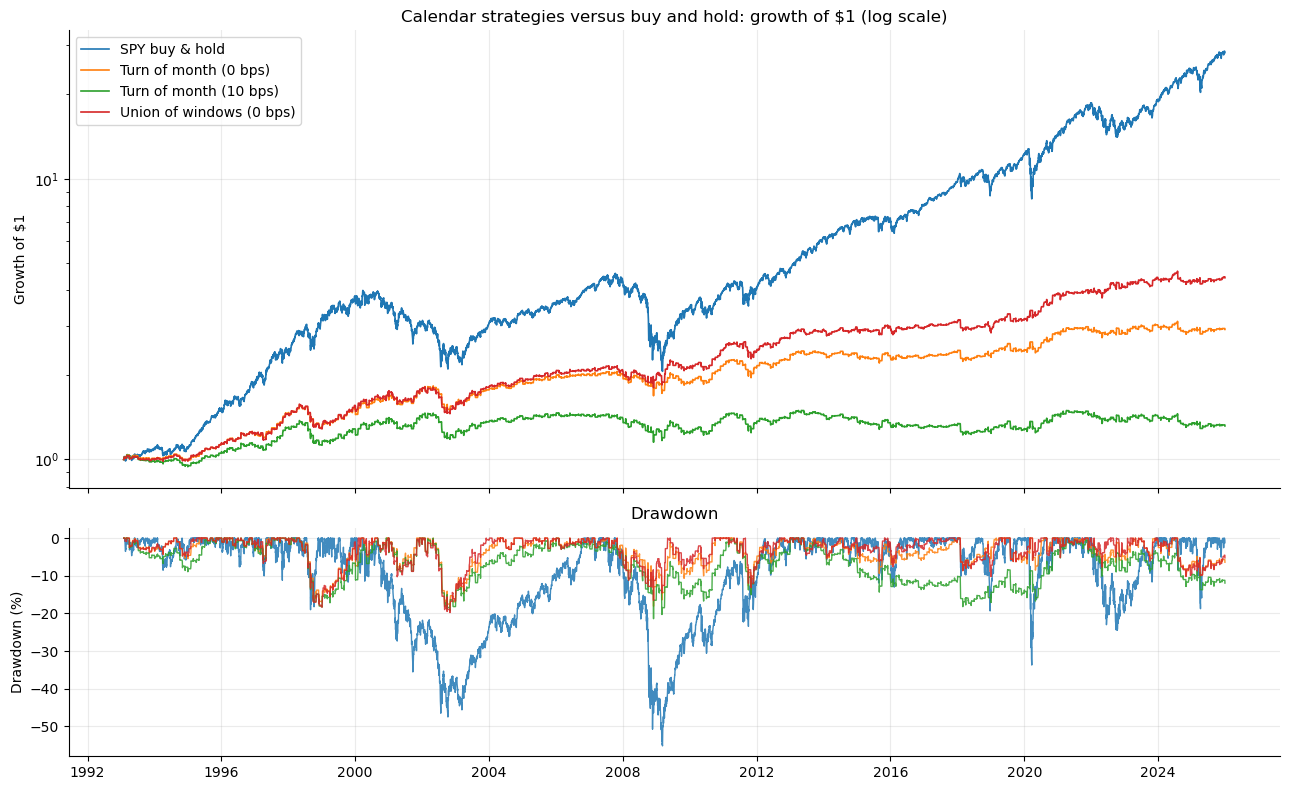

In [5]:
union_mask = masks["Turn of month"] | masks["Pre-holiday"] | masks["Pre-FOMC (2011+)"]
union_rows = []
for cost_bps in (0, 2, 10):
    result = mask_strategy(union_mask, cost_bps)
    metrics = result.metrics
    union_rows.append({"strategy": f"Union of windows @ {cost_bps} bps", "sharpe_ratio": metrics["sharpe_ratio"], "annualized_return": metrics["annualized_return"], "max_drawdown": metrics["max_drawdown"], "exposure": float(union_mask.mean()), "annualized_turnover": metrics["annualized_turnover"]})
union_rows.append({"strategy": "SPY buy & hold", "sharpe_ratio": buy_and_hold.metrics["sharpe_ratio"], "annualized_return": buy_and_hold.metrics["annualized_return"], "max_drawdown": buy_and_hold.metrics["max_drawdown"], "exposure": 1.0, "annualized_turnover": 0.0})
display(pd.DataFrame(union_rows).set_index("strategy").style.format({
    "sharpe_ratio": "{:.2f}", "annualized_return": "{:.2%}", "max_drawdown": "{:.2%}",
    "exposure": "{:.1%}", "annualized_turnover": "{:.1f}",
}))

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
series = {
    "SPY buy & hold": buy_and_hold.frame["equity"],
    "Turn of month (0 bps)": mask_strategy(masks["Turn of month"], 0).frame["equity"],
    "Turn of month (10 bps)": mask_strategy(masks["Turn of month"], 10).frame["equity"],
    "Union of windows (0 bps)": mask_strategy(union_mask, 0).frame["equity"],
}
for label, equity in series.items():
    axes[0].plot(equity.index, equity / equity.iloc[0], label=label, lw=1.2)
    axes[1].plot(equity.index, 100 * (equity / equity.cummax() - 1), lw=1.0, alpha=0.85)
axes[0].set_yscale("log")
axes[0].set_title("Calendar strategies versus buy and hold: growth of $1 (log scale)")
axes[0].set_ylabel("Growth of $1")
axes[0].legend()
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown (%)")
plt.tight_layout()

## 🕰️ Did the effect decay?

Anomalies that are published and then arbitraged should show a break. The turn-of-month window is the cleanest case to test because it has the longest record: split SPY's history into three blocks and compare the in-window per-day return with the rest.

,turn-of-month inside (bps),turn-of-month outside (bps),turn-of-month t,pre-holiday inside (bps),pre-holiday t
block,,,,,
1993-2005,11.46,2.85,+1.72,5.00,+0.05
2006-2015,4.31,3.46,+0.14,10.53,+0.63
2016-2025,5.27,6.31,-0.19,18.26,+1.60


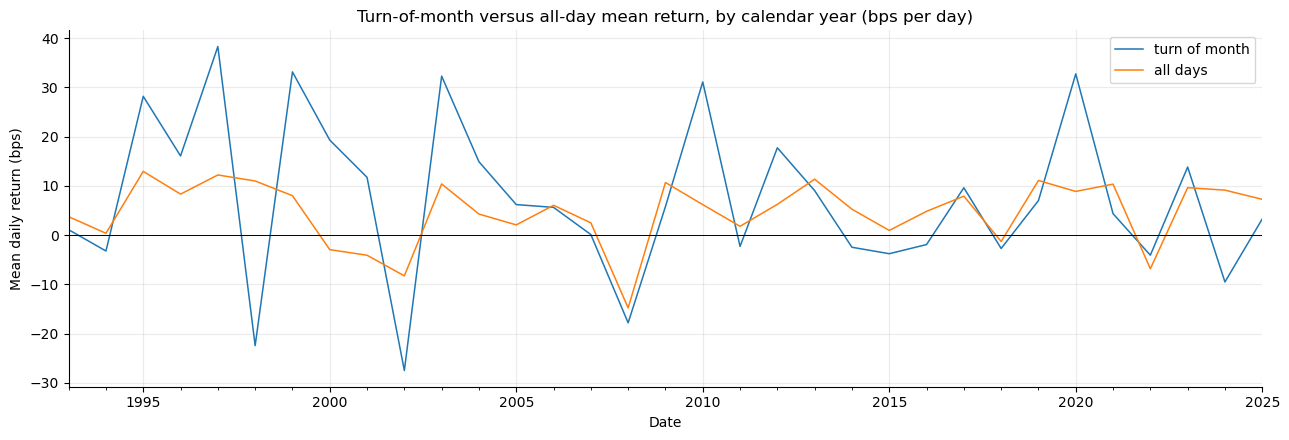

In [6]:
blocks = {"1993-2005": ("1993", "2005"), "2006-2015": ("2006", "2015"), "2016-2025": ("2016", "2025")}
decay_rows = []
for label, (start, end) in blocks.items():
    window = returns.loc[start:end]
    block_mask = masks["Turn of month"].reindex(window.index).fillna(False).astype(bool)
    holiday_mask = masks["Pre-holiday"].reindex(window.index).fillna(False).astype(bool)
    decay_rows.append({
        "block": label,
        "turn-of-month inside (bps)": float(window[block_mask].mean() * 10_000),
        "turn-of-month outside (bps)": float(window[~block_mask].mean() * 10_000),
        "turn-of-month t": welch_t(window[block_mask], window[~block_mask]),
        "pre-holiday inside (bps)": float(window[holiday_mask].mean() * 10_000),
        "pre-holiday t": welch_t(window[holiday_mask], window[~holiday_mask]),
    })
display(pd.DataFrame(decay_rows).set_index("block").style.format({
    "turn-of-month inside (bps)": "{:.2f}", "turn-of-month outside (bps)": "{:.2f}",
    "turn-of-month t": "{:+.2f}", "pre-holiday inside (bps)": "{:.2f}", "pre-holiday t": "{:+.2f}",
}).set_caption("Subperiod decay check"))

yearly = pd.DataFrame({
    "turn of month": returns[masks["Turn of month"].reindex(returns.index).fillna(False).astype(bool)].resample("YE").mean() * 10_000,
    "all days": returns.resample("YE").mean() * 10_000,
})
ax = yearly.plot(figsize=(13, 4.5), lw=1.1)
ax.axhline(0, color="black", lw=0.7)
ax.set_title("Turn-of-month versus all-day mean return, by calendar year (bps per day)")
ax.set_ylabel("Mean daily return (bps)")
plt.tight_layout()

## 🎛️ Robustness: is the FOMC sample long enough to say anything?

The pre-FOMC mask only has about eight observations per year since 2011, so the test has very little power. This cell makes that explicit rather than hiding it behind a Sharpe ratio.

In [7]:
fomc_dates = scheduled_fomc_dates()
fomc_in_range = fomc_dates[(fomc_dates >= close.index[0]) & (fomc_dates <= close.index[-1])]
fomc_mask = masks["Pre-FOMC (2011+)"].reindex(returns.index).fillna(False).astype(bool)
inside = returns[fomc_mask]

standard_error = inside.std(ddof=1) / np.sqrt(len(inside))
summary = pd.Series({
    "scheduled announcements in sample": len(fomc_in_range),
    "mean announcement-day return (bps)": float(inside.mean() * 10_000),
    "standard error (bps)": float(standard_error * 10_000),
    "t-statistic vs zero": float(inside.mean() / standard_error),
    "all other days (bps)": float(returns[~fomc_mask].mean() * 10_000),
    "cumulative return on announcement days": float((1.0 + inside).prod() - 1.0),
})
display(summary.to_frame("value").style.format("{:.2f}"))

# Emergency statements are excluded by default; include them as a sensitivity.
with_emergency = pre_fomc_mask(returns.index, include_unscheduled=True)
included = returns[with_emergency.reindex(returns.index).fillna(False).astype(bool)]
print(f"Including emergency statements changes the sample from {len(inside)} to {len(included)} days "
      f"and the mean from {inside.mean() * 10_000:.2f} bps to {included.mean() * 10_000:.2f} bps.")

,value
scheduled announcements in sample,120.00
mean announcement-day return (bps),15.76
standard error (bps),10.49
t-statistic vs zero,1.50
all other days (bps),4.55
cumulative return on announcement days,0.20


Including emergency statements changes the sample from 120 to 125 days and the mean from 15.76 bps to 11.65 bps.


## ✅ Method checks

The calendar machinery is the part most likely to be silently wrong, so these checks assert it: holidays match a known year, the turn-of-month window has the right size, and the position shift really earns exactly the masked days.

In [8]:
checks = {}
checks["2024 holiday list matches the exchange calendar"] = list(nyse_holidays(2024, 2024)) == list(pd.DatetimeIndex([
    "2024-01-01", "2024-01-15", "2024-02-19", "2024-03-29", "2024-05-27",
    "2024-06-19", "2024-07-04", "2024-09-02", "2024-11-28", "2024-12-25",
]))
checks["turn-of-month window is 4 of every 21 trading days"] = bool(abs(float(masks["Turn of month"].mean()) - 4.0 / 21.0) < 0.03)
checks["no Columbus Day or Veterans Day pre-holiday masks"] = not any(
    timestamp in set(close.index[masks["Pre-holiday"]]) for timestamp in [pd.Timestamp("2020-10-09"), pd.Timestamp("2020-11-10")]
)
checks["every scheduled FOMC date is a trading day"] = bool(pd.DatetimeIndex([d for d in scheduled_fomc_dates() if close.index[0] <= d <= close.index[-1]]).isin(close.index).all())
checks["weekday masks partition trading days"] = int(sum(int(masks[name].sum()) for name in ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])) == len(close.index)

synthetic_returns = pd.Series(np.where(masks["Turn of month"].to_numpy(), 0.01, 0.0), index=close.index)
synthetic_close = 100.0 * (1.0 + synthetic_returns).cumprod()
synthetic_result = run_backtest(synthetic_close, positions_from_return_mask(masks["Turn of month"]), transaction_cost_bps=0.0)
capturable = int(masks["Turn of month"].sum()) - int(bool(masks["Turn of month"].iloc[0]))
checks["position shift earns exactly the masked days"] = bool(np.isclose(synthetic_result.metrics["total_return_after_costs"], 1.01 ** capturable - 1.0, atol=1e-9))
checks["mask strategies never exceed full investment"] = all(float(mask_strategy(mask, 10).frame["held_position"].abs().max()) <= 1.0 + 1e-12 for mask in masks.values())
display(pd.Series(checks, name="passed").to_frame().replace({True: "✅", False: "❌"}))

,passed
2024 holiday list matches the exchange calendar,✅
turn-of-month window is 4 of every 21 trading days,✅
no Columbus Day or Veterans Day pre-holiday masks,✅
every scheduled FOMC date is a trading day,✅
weekday masks partition trading days,✅
position shift earns exactly the masked days,✅
mask strategies never exceed full investment,✅


## ⚖️ What went well / what went wrong

### ✅ What went well

- **The calendar machinery is exact and testable.** NYSE closures are computed (including Easter and the weekend observance rules), not hardcoded; FOMC dates are frozen from the Fed's own pages; and a synthetic-return test proves that the position shift earns precisely the masked days — the classic off-by-one error cannot hide here.
- **The three event effects point in the documented direction.** Turn-of-month days average 7.4 bps against 4.1 bps, pre-holiday 10.9 against 4.5, pre-FOMC 15.8 against 4.6. Monday, Wednesday and Friday are indistinguishable from the rest; Thursday is mildly negative. The repeated sign across independent studies is not nothing.
- **The decay evidence is visible.** Turn-of-month in-window returns fell from 11.5 bps (1993–2005, t = 1.7) to 4.3 bps (2006–2015, t = 0.1) to 5.3 bps against 6.3 bps outside the window (2016–2025, t = -0.2). That is what a published and arbitraged anomaly is supposed to look like.
- **The FOMC drift is far weaker than the paper.** 15.8 bps per announcement day against the ~49 bps in Lucca and Moench's original sample, which is consistent with post-publication decay and with a much shorter sample here.

### ❌ What went wrong

- **Nothing is statistically significant.** No effect clears |t| = 1.3 on a two-sample difference of means: turn-of-month +1.03, pre-holiday +1.13, pre-FOMC +1.06, and the weekday spread runs from -1.21 (Thursday) to +0.99 (Tuesday). These are hints, not findings.
- **No calendar strategy beats buy and hold after costs.** At 0 bps the turn-of-month rule earns 0.45 Sharpe against 0.64; at 10 bps it collapses to 0.15. Pre-holiday goes from 0.34 to -0.29. The union of all windows earns 0.58 before costs and 0.11 after.
- **Cash drag is the binding constraint.** Being invested 19.1% of the time cuts the annualised return from 10.68% to 3.30% while volatility falls far less than proportionally, and the resulting Sharpe ratio cannot compete with full exposure.
- **Weekday effects are noise in this sample**, with Thursday mildly negative — the opposite of the folk "Monday effect" and not significant either.
- **The FOMC sample has almost no power.** 120 announcement days with a standard error of 10.5 bps: t = 1.5 against zero and t = 1.1 against other days. The point estimate is 11 bps above the average day, and the interval comfortably contains both zero and a much larger effect.

### 🔍 What this teaches

1. A conditional mean is not an edge. 11 bps on 19% of days is not a strategy; it is a description.
2. Costs scale with turnover, not with time invested. A four-day window per month pays two round trips a month, which is why the turn-of-month rule dies at 10 bps while buy-and-hold pays nothing.
3. Compute the calendar. Hardcoded holiday or meeting dates are a silent error source, and Easter plus the observance rules are 30 lines of code.
4. Report the number of observations next to the t-statistic. "0.30 Sharpe over 120 days" is a much weaker statement than it looks.

### ⚠️ Limitations

- One asset (SPY) and one implementation. The effects are documented across indices and countries; that replication is not done here.
- The FOMC date list starts in 2011 because that is the range extracted and frozen; the original paper's sample starts in 1994.
- Daily close-to-close returns only. Lucca and Moench measure a 24-hour window around the 2pm announcement, which intraday data would pin down more precisely.
- No taxes, no bid-ask spread variation, and 10 bps is punitive for modern SPY but that is the repository default.
- Multiple testing: four effects plus five weekdays on one sample means some apparent significance would be expected by chance. None was found, which is the honest outcome.

In [9]:
validation = pd.Series({
    "notebook executed top to bottom": True,
    "one-bar execution delay (shared backtester)": True,
    "calendar dates known in advance, documented in the module": True,
    "NYSE holidays computed, not hardcoded": bool(checks["2024 holiday list matches the exchange calendar"]),
    "position shift verified on synthetic data": bool(checks["position shift earns exactly the masked days"]),
    "cost sensitivity at 0 / 2 / 10 bps": True,
    "t-statistics and sample sizes reported, not just Sharpe": True,
    "negative results kept": True,
})
display(validation.to_frame("status"))
print(data_source)

,status
notebook executed top to bottom,True
one-bar execution delay (shared backtester),True
"calendar dates known in advance, documented in the module",True
"NYSE holidays computed, not hardcoded",True
position shift verified on synthetic data,True
cost sensitivity at 0 / 2 / 10 bps,True
"t-statistics and sample sizes reported, not just Sharpe",True
negative results kept,True


Yahoo Finance adjusted daily ETF close
